# Weather and daily micromobility crossings in Seattle
**CISC7204 Practice 09 — Guo Jinzheng**  
Region: Seattle, Washington, United States. Domain: urban transportation and weather.

**Question:** During 2022–2024, how are precipitation and temperature associated with recorded Fremont Bridge crossings after adjusting for calendar factors?

This notebook uses real government observations, not simulated data. The current city title includes bicycles and scooters; crossings are not unique riders or confirmed commute trips. NOAA Seattle Tacoma Airport is a regional weather proxy.

## Run instructions
Clone or download this repository, keep this notebook beside `data/`, and open it in Jupyter with Python 3.12 or later. Install dependencies with `python -m pip install -r requirements.txt`, select that Python kernel, then **Restart Kernel and Run All Cells**. Data snapshots are included, so normal execution works offline. Missing raw files can be downloaded from their recorded URLs; changed upstream bytes are rejected until explicitly reviewed. Outputs are written into `results/`.

Sources: [Seattle dataset](https://cos-data.seattle.gov/d/65db-xm6k), [NOAA station](https://www.ncei.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND:USW00024233/detail), [NOAA record layout](https://www.ncei.noaa.gov/pub/data/ghcn/daily/readme.txt).

In [1]:
from pathlib import Path
import calendar, hashlib, json, urllib.request, warnings, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from patsy import dmatrices
from pandas.tseries.holiday import USFederalHolidayCalendar
from IPython.display import display

ROOT = Path.cwd()
DATA, RESULTS = ROOT / 'data', ROOT / 'results'
assert (DATA / 'source_manifest.json').exists(), 'Run from the extracted package directory containing data/.'
RESULTS.mkdir(exist_ok=True)
START, END = pd.Timestamp('2022-01-01'), pd.Timestamp('2024-12-31')
CALENDAR = pd.date_range(START, END, freq='D')
manifest = json.loads((DATA / 'source_manifest.json').read_text())
for name, info in manifest['files'].items():
    target = DATA / name
    if not target.exists():
        request = urllib.request.Request(info['url'], headers={'User-Agent':'CISC7204 educational analysis'})
        target.write_bytes(urllib.request.urlopen(request, timeout=90).read())
    assert hashlib.sha256(target.read_bytes()).hexdigest() == info['sha256'], f'Data snapshot changed: {name}'
versions = {name:importlib.metadata.version(name) for name in ['numpy','pandas','matplotlib','scipy','statsmodels','patsy']}
print('Data snapshot retrieval:', manifest['retrieved_utc'])
print('Package versions:', versions)
plt.rcParams.update({'font.size':11, 'axes.titlesize':12, 'axes.spines.top':False,
                     'axes.spines.right':False, 'figure.dpi':120})

Data snapshot retrieval: 2026-09-18T08:45:53.494331+00:00
Package versions: {'numpy': '2.5.3', 'pandas': '3.0.6', 'matplotlib': '3.11.2', 'scipy': '1.18.1', 'statsmodels': '0.15.0', 'patsy': '1.0.3'}


## 1 Counter validation and daily aggregation
The API returns timezone-free calendar timestamps. We use its reported date and do not invent a UTC conversion. We compare the published total with the sum of the two pathways and count valid hourly values. Missing hours are not replaced by zero. All six US daylight-saving transition dates are excluded from the primary model because clock conventions differ; the spring dates each contain one missing hourly value. Autumn transition dates have 24 published values, which does not reveal how the repeated hour was handled. We test retaining those dates later. Genuine very low counts remain in the primary sample.

In [2]:
raw = pd.read_csv(DATA / 'fremont_2022_2024_raw.csv', parse_dates=['date'])
required = ['date','fremont_bridge','fremont_bridge_nb','fremont_bridge_sb']
assert set(required).issubset(raw.columns)
assert not raw['date'].duplicated().any(), 'Duplicate timestamps need review.'
assert raw['date'].between(START, END + pd.Timedelta(hours=23)).all()
for c in required[1:]:
    raw[c] = pd.to_numeric(raw[c], errors='raise')
    assert (raw[c].dropna() >= 0).all()
    assert np.allclose(raw[c].dropna(), np.round(raw[c].dropna()))
valid = raw[required[1:]].notna().all(axis=1)
assert np.allclose(raw.loc[valid,'fremont_bridge'],
                   raw.loc[valid,'fremont_bridge_nb'] + raw.loc[valid,'fremont_bridge_sb'])
raw['day'] = raw['date'].dt.normalize()
counter = raw.groupby('day').agg(crossings=('fremont_bridge','sum'),
                                valid_hours=('fremont_bridge','count'),
                                rows=('fremont_bridge','size')).reindex(CALENDAR)
counter.index.name = 'date'
dst_dates = pd.to_datetime(['2022-03-13','2022-11-06','2023-03-12','2023-11-05','2024-03-10','2024-11-03'])
counter['dst_transition'] = counter.index.isin(dst_dates)
counter['complete_counter'] = counter['valid_hours'].eq(24) & counter['rows'].eq(24)
print('Hourly rows:', len(raw), '| Missing total values:', int(raw['fremont_bridge'].isna().sum()))
display(counter.loc[~counter['complete_counter'], ['crossings','valid_hours','rows']])

Hourly rows: 26304 | Missing total values: 14


,crossings,valid_hours,rows
date,,,
2022-03-13,1295.0,23,24
2023-03-12,705.0,23,24
2023-04-18,1215.0,13,24
2024-03-10,489.0,23,24


## 2 Weather parsing and quality checks
NOAA's `.dly` file contains monthly fixed-width records. We extract TMAX, TMIN and PRCP, convert tenths of degrees Celsius or millimetres to physical units, reject `-9999` and nonblank quality flags, and preserve trace flags. Trace precipitation is encoded as zero and therefore belongs to the below-1-mm group. Temperature is the midpoint of daily maximum and minimum, not a measured mean. Calendar dates are joined as reported by the two providers; possible differences in observation windows remain a limitation.

In [3]:
weather_records = []
for line in (DATA / 'USW00024233.dly').read_text().splitlines():
    station, year, month, element = line[:11], int(line[11:15]), int(line[15:17]), line[17:21]
    if station != 'USW00024233' or year not in [2022,2023,2024] or element not in ['TMAX','TMIN','PRCP']:
        continue
    for day in range(1, calendar.monthrange(year,month)[1]+1):
        offset = 21 + (day-1)*8
        value = int(line[offset:offset+5])
        measurement, quality, source = line[offset+5:offset+8]
        good = value != -9999 and quality == ' '
        weather_records.append({'date':pd.Timestamp(year,month,day), 'element':element,
                                'value':value/10 if good else np.nan,
                                'raw_value':value, 'measurement_flag':measurement,
                                'quality_flag':quality, 'source_flag':source})
weather_long = pd.DataFrame(weather_records)
assert not weather_long.duplicated(['date','element']).any()
weather = weather_long.pivot(index='date',columns='element',values='value').reindex(CALENDAR)
weather = weather.rename(columns={'TMAX':'tmax_c','TMIN':'tmin_c','PRCP':'precip_mm'})
weather['temp_mid_c'] = (weather['tmax_c'] + weather['tmin_c'])/2
assert (weather['precip_mm'].dropna()>=0).all()
temperature_pairs = weather[['tmax_c','tmin_c']].dropna()
assert (temperature_pairs['tmax_c']>=temperature_pairs['tmin_c']).all()
print('Missing weather values:',weather[['precip_mm','tmax_c','tmin_c']].isna().sum().to_dict())
print('Rejected quality flags:',int(weather_long['quality_flag'].ne(' ').sum()))
display(weather.loc[weather[['precip_mm','tmax_c','tmin_c']].isna().any(axis=1)])
weather_long.to_csv(RESULTS/'weather_parsed.csv',index=False)

Missing weather values: {'precip_mm': 2, 'tmax_c': 0, 'tmin_c': 1}
Rejected quality flags: 0


element,precip_mm,tmax_c,tmin_c,temp_mid_c
date,,,,
2024-04-24,NaN,12.2,7.8,10.0
2024-04-25,NaN,11.7,NaN,NaN


## 3 Join and sample audit
Wet means precipitation **at least 1 mm**; the reference is below 1 mm, which can include light rain. We exclude incomplete counter days, all six daylight-saving transition dates, and days missing any required weather field. Exclusion counts below can overlap, so the union determines the final sample. Month, year, day of week and observed US federal-holiday indicators are included as calendar controls.

In [4]:
daily = counter.join(weather, how='left')
daily['weather_complete'] = daily[['precip_mm','tmax_c','tmin_c']].notna().all(axis=1)
daily['include_primary'] = daily['complete_counter'] & ~daily['dst_transition'] & daily['weather_complete']
daily['wet'] = (daily['precip_mm']>=1).astype(int)
daily['month'], daily['year'], daily['dow'] = daily.index.month, daily.index.year, daily.index.dayofweek
holidays = USFederalHolidayCalendar().holidays(START, END)
daily['holiday'] = daily.index.isin(holidays).astype(int)
daily['temp_c'] = (daily['temp_mid_c']-15)/10  # centered and scaled for numerical stability
analysis = daily.loc[daily['include_primary']].copy()
assert analysis.index.is_unique and analysis.index.is_monotonic_increasing
audit = {'expected_days':len(daily), 'raw_hourly_rows':len(raw),
         'missing_counter_hours':int(raw['fremont_bridge'].isna().sum()),
         'incomplete_counter_days':int((~daily['complete_counter']).sum()),
         'dst_transition_days':int(daily['dst_transition'].sum()),
         'missing_weather_days':int((~daily['weather_complete']).sum()),
         'excluded_union_days':int((~daily['include_primary']).sum()),
         'primary_days':len(analysis)}
print(json.dumps(audit,indent=2))
display(daily.loc[~daily['include_primary'], ['valid_hours','dst_transition','precip_mm','tmax_c','tmin_c']])
daily.to_csv(RESULTS/'daily_joined_with_audit.csv',index_label='date')
analysis.to_csv(RESULTS/'analysis_daily.csv',index_label='date')
groups = analysis.groupby('wet')['crossings'].agg(['count','mean','median','std'])
groups.index = ['Below 1 mm','At least 1 mm']
groups.to_csv(RESULTS/'weather_group_summary.csv')
display(groups.round(2))
raw_ratio = groups.loc['At least 1 mm','mean']/groups.loc['Below 1 mm','mean']
correlation = analysis['temp_mid_c'].corr(analysis['crossings'])
print(f'Unadjusted wet-day mean ratio: {raw_ratio:.4f}; temperature Pearson r: {correlation:.4f}')

{
  "expected_days": 1096,
  "raw_hourly_rows": 26304,
  "missing_counter_hours": 14,
  "incomplete_counter_days": 4,
  "dst_transition_days": 6,
  "missing_weather_days": 2,
  "excluded_union_days": 9,
  "primary_days": 1087
}


,valid_hours,dst_transition,precip_mm,tmax_c,tmin_c
date,,,,,
2022-03-13,23,True,2.5,11.7,3.9
2022-11-06,24,True,19.3,7.2,3.3
2023-03-12,23,True,6.1,8.3,-0.5
2023-04-18,13,False,3.0,8.9,3.3
2023-11-05,24,True,7.9,15.6,7.8
2024-03-10,23,True,5.3,10.0,6.1
2024-04-24,24,False,NaN,12.2,7.8
2024-04-25,24,False,NaN,11.7,NaN
2024-11-03,24,True,0.3,11.1,7.2


,count,mean,median,std
Below 1 mm,743,2821.56,2831.0,1015.65
At least 1 mm,344,1527.72,1461.5,766.19


Unadjusted wet-day mean ratio: 0.5414; temperature Pearson r: 0.7134


## 4 Adjusted negative binomial model
We estimate a log-linked NB2 model: expected crossings depend on wet-day status, centered temperature and its square, with categorical month, year and weekday controls plus observed holidays. The dispersion parameter is estimated rather than assumed. `exp(wet coefficient)` is an adjusted expected-count ratio, conditional on this model. The temperature curve reports the expected-count ratio relative to 15°C, holding other model terms fixed. These are associations, not causal effects. We do not select controls according to statistical significance. The printed model summary contains default independent-observation standard errors; use the time-aware bootstrap intervals in Section 5 for the reported inferences.

In [5]:
FORMULA = 'crossings ~ wet + temp_c + I(temp_c ** 2) + C(month) + C(year) + C(dow) + holiday'
y, X = dmatrices(FORMULA, analysis, return_type='dataframe')
model = sm.NegativeBinomial(y.iloc[:,0], X).fit(method='bfgs',maxiter=400,disp=False)
assert model.mle_retvals['converged'], 'Model did not converge.'
assert np.isfinite(model.params).all() and model.params['alpha']>0
print(model.summary())
(RESULTS/'negative_binomial_summary.txt').write_text(str(model.summary()))
coef = pd.DataFrame({'coefficient':model.params,'model_se':model.bse})
coef.to_csv(RESULTS/'model_coefficients.csv')
mu = model.predict(X)
residual = (analysis['crossings']-mu)/np.sqrt(mu+model.params['alpha']*mu**2)
calendar_residual = residual.reindex(CALENDAR)
diagnostics = {'alpha':float(model.params['alpha']),
               'pearson_residual_mean_square':float(np.mean(residual**2)),
               'residual_lag1':float(calendar_residual.autocorr(1)),
               'residual_lag7':float(calendar_residual.autocorr(7)),
               'in_sample_mae':float(np.mean(np.abs(analysis['crossings']-mu))),
               'design_condition_number':float(np.linalg.cond(X)),
               'converged':bool(model.mle_retvals['converged'])}
print('Diagnostics:',diagnostics)

                     NegativeBinomial Regression Results                      
Dep. Variable:              crossings   No. Observations:                 1087
Model:               NegativeBinomial   Df Residuals:                     1063
Method:                           MLE   Df Model:                           23
Date:                Fri, 18 Sep 2026   Pseudo R-squ.:                 0.08144
Time:                        16:53:25   Log-Likelihood:                -8463.0
converged:                       True   LL-Null:                       -9213.3
Covariance Type:            nonrobust   LLR p-value:                1.801e-303
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           7.7414      0.050    154.783      0.000       7.643       7.839
C(month)[T.2]       0.1241      0.041      3.007      0.003       0.043       0.205
C(month)[T.3]       0.1993      

## 5 Time-aware uncertainty and sensitivity checks
We use a circular moving-block bootstrap on the **full calendar**, retaining missing-day gaps inside blocks, and resample consecutive 14-day blocks. Each replicate refits all model parameters including dispersion. The random seed is fixed. Primary intervals are percentile intervals from 300 successful attempts (failed fits, if any, are counted). Block lengths 7 and 28 use 150 attempts each as sensitivity checks; these shorter runs give less precise interval endpoints. Further checks retain clock-transition days, exclude the lowest 1% of counts, and replace the wet indicator by continuous precipitation. This is a preliminary analysis; bootstrap intervals do not remove unmeasured confounding or seasonal model misspecification.

In [6]:
B_MAIN, B_SENS = 300, 150
calendar_positions = pd.Series(np.arange(len(analysis)),index=analysis.index).reindex(CALENDAR).fillna(-1).to_numpy(int)
def block_bootstrap(block_length, attempts, seed):
    rng = np.random.default_rng(seed)
    params, failed = [], 0
    n = len(CALENDAR)
    for _ in range(attempts):
        starts = rng.integers(0,n,size=int(np.ceil(n/block_length)))
        calendar_idx = ((starts[:,None]+np.arange(block_length))%n).ravel()[:n]
        positions = calendar_positions[calendar_idx]
        positions = positions[positions>=0]
        try:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                fitted = sm.NegativeBinomial(y.iloc[positions,0].to_numpy(),X.iloc[positions].to_numpy()).fit(
                    start_params=model.params.to_numpy(),method='bfgs',maxiter=250,disp=False)
            if not fitted.mle_retvals['converged'] or not np.isfinite(fitted.params).all():
                failed += 1
            else:
                params.append(fitted.params)
        except (ValueError, np.linalg.LinAlgError):
            failed += 1
    assert len(params)>=0.9*attempts, 'Too many bootstrap failures.'
    print(f'Block {block_length}: {len(params)} successful fits; {failed} failed attempts')
    return pd.DataFrame(params,columns=model.params.index), failed

boot, failed_main = block_bootstrap(14,B_MAIN,7204)
boot.to_csv(RESULTS/'bootstrap_parameters.csv',index=False)
wet_ratio = float(np.exp(model.params['wet']))
wet_ci = np.quantile(np.exp(boot['wet']),[0.025,0.975])
def temp_ratio(params, celsius):
    z=(np.asarray(celsius)-15)/10
    return np.exp(params['temp_c']*z+params['I(temp_c ** 2)']*z**2)
temp20ratio = float(temp_ratio(model.params,20))
temp20ci = np.quantile(temp_ratio(boot,20),[0.025,0.975])
effect_table = pd.DataFrame([
    ['Wet versus below 1 mm',wet_ratio,wet_ci[0],wet_ci[1]],
    ['20 C versus 15 C',temp20ratio,temp20ci[0],temp20ci[1]]
],columns=['contrast','count_ratio','ci_low','ci_high'])
display(effect_table.round(4))
effect_table.to_csv(RESULTS/'primary_effects.csv',index=False)
sens_rows = [['Primary 14-day blocks',len(analysis),wet_ratio,wet_ci[0],wet_ci[1],len(boot)]]
for block, seed in [(7,7205),(28,7206)]:
    b,failed = block_bootstrap(block,B_SENS,seed)
    ci = np.quantile(np.exp(b['wet']),[0.025,0.975])
    sens_rows.append([f'{block}-day blocks',len(analysis),wet_ratio,ci[0],ci[1],len(b)])

def fit_subset(frame, formula=FORMULA):
    yy,xx=dmatrices(formula,frame,return_type='dataframe')
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        m=sm.NegativeBinomial(yy.iloc[:,0],xx).fit(method='bfgs',maxiter=400,disp=False)
    assert m.mle_retvals['converged']
    return m
clock_frame = daily.loc[daily['weather_complete'] &
              (daily['complete_counter'] | (daily['dst_transition'] & daily['valid_hours'].eq(23)))].copy()
clock_model=fit_subset(clock_frame)
low_cut = analysis['crossings'].quantile(0.01)
trim_frame=analysis.loc[analysis['crossings']>=low_cut]
trim_model=fit_subset(trim_frame)
continuous_model=fit_subset(analysis,FORMULA.replace('wet','precip_mm'))
sens_rows += [['Retain clock transition days',len(clock_frame),float(np.exp(clock_model.params['wet'])),np.nan,np.nan,0],
              ['Exclude lowest 1 percent',len(trim_frame),float(np.exp(trim_model.params['wet'])),np.nan,np.nan,0]]
sensitivity=pd.DataFrame(sens_rows,columns=['specification','days','wet_ratio','ci_low','ci_high','successful_bootstraps'])
sensitivity.to_csv(RESULTS/'sensitivity_results.csv',index=False)
display(sensitivity.round(4))
print('Continuous precipitation count ratio per +1 mm:',float(np.exp(continuous_model.params['precip_mm'])))

Block 14: 300 successful fits; 0 failed attempts


,contrast,count_ratio,ci_low,ci_high
0,Wet versus below 1 mm,0.6562,0.6187,0.6926
1,20 C versus 15 C,1.0958,1.0619,1.1385


Block 7: 150 successful fits; 0 failed attempts


Block 28: 150 successful fits; 0 failed attempts


,specification,days,wet_ratio,ci_low,ci_high,successful_bootstraps
0,Primary 14-day blocks,1087,0.6562,0.6187,0.6926,300
1,7-day blocks,1087,0.6562,0.6309,0.6877,150
2,28-day blocks,1087,0.6562,0.6218,0.6958,150
3,Retain clock transition days,1093,0.6553,NaN,NaN,0
4,Exclude lowest 1 percent,1076,0.6667,NaN,NaN,0


Continuous precipitation count ratio per +1 mm: 0.9709385812987126


## 6 Visual evidence
Panel A shows the recorded daily series and a 30-day rolling mean (at least 20 usable days). Panel B shows raw weather-count observations. Panel C shows the adjusted wet-day count ratio with a 95% block-bootstrap interval, alongside the unadjusted mean ratio. Panel D shows the adjusted temperature ratio relative to 15°C with a pointwise 95% interval, limited to the central 95% of observed temperatures. The shaded band is not a prediction interval and is not simultaneous across all temperatures.

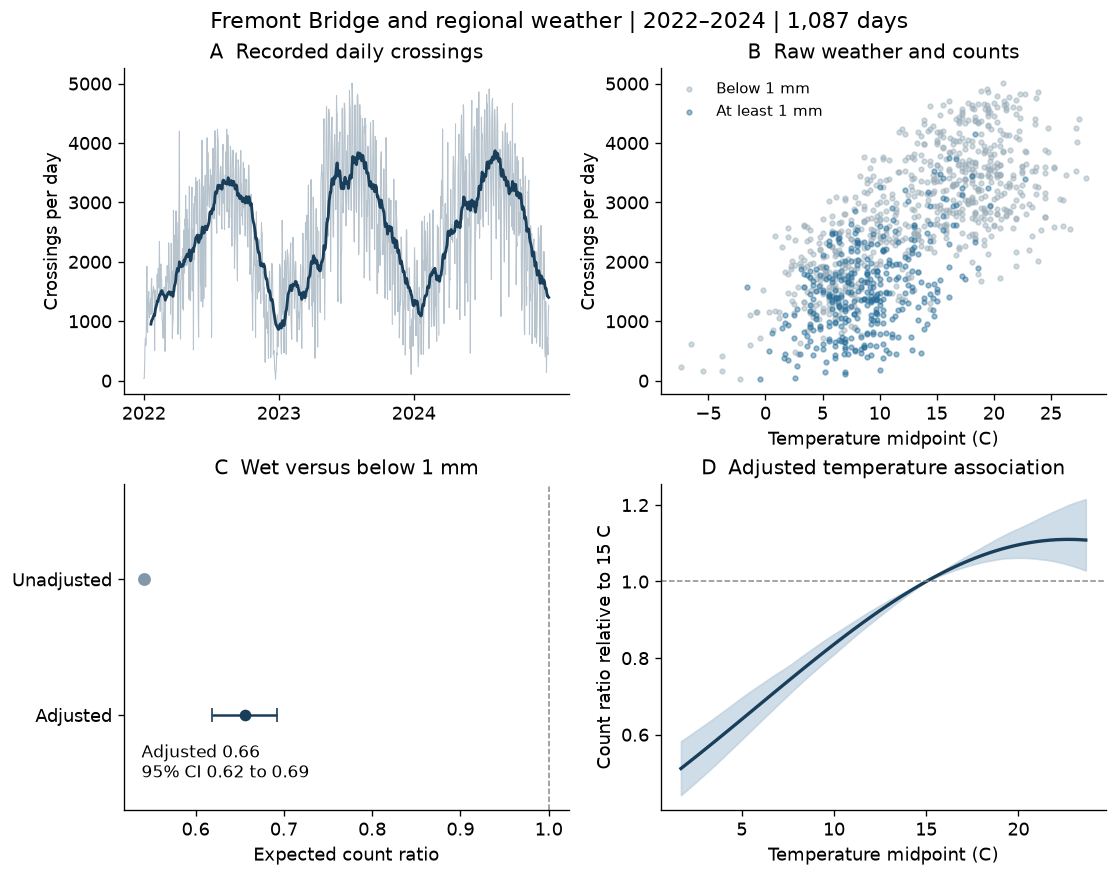

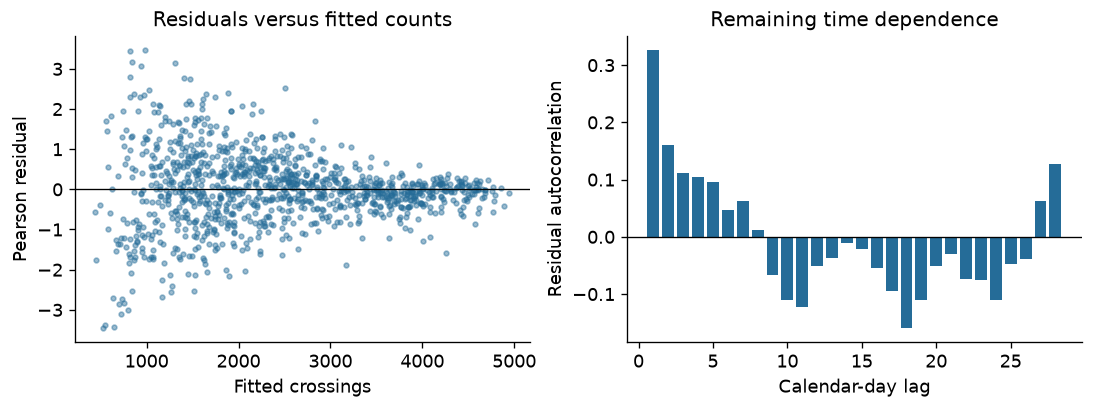

In [7]:
fig, ax=plt.subplots(2,2,figsize=(9.2,7.2),constrained_layout=True)
colors={0:'#9AADB9',1:'#256C98'}
series=analysis['crossings'].reindex(CALENDAR)
ax[0,0].plot(series.index,series,color='#B7C3CD',linewidth=0.65)
ax[0,0].plot(series.index,series.rolling(30,min_periods=20).mean(),color='#193E5A',linewidth=1.7)
ax[0,0].set(title='A  Recorded daily crossings',ylabel='Crossings per day')
ax[0,0].set_xticks(pd.to_datetime(['2022-01-01','2023-01-01','2024-01-01']))
ax[0,0].set_xticklabels(['2022','2023','2024'])
for wet,label in [(0,'Below 1 mm'),(1,'At least 1 mm')]:
    d=analysis.loc[analysis['wet']==wet]
    ax[0,1].scatter(d['temp_mid_c'],d['crossings'],s=8,alpha=0.45,color=colors[wet],label=label,rasterized=True)
ax[0,1].set(title='B  Raw weather and counts',xlabel='Temperature midpoint (C)',ylabel='Crossings per day')
ax[0,1].legend(fontsize=9,frameon=False,loc='upper left')
ax[1,0].scatter(raw_ratio,1,s=45,color='#8198A9',label='Unadjusted mean ratio')
ax[1,0].errorbar(wet_ratio,0,xerr=[[wet_ratio-wet_ci[0]],[wet_ci[1]-wet_ratio]],fmt='o',color='#193E5A',capsize=4)
ax[1,0].axvline(1,color='#888888',linestyle='--',linewidth=0.9)
ax[1,0].set_yticks([0,1],['Adjusted','Unadjusted'])
ax[1,0].set_ylim(-0.7,1.7)
ax[1,0].set(title='C  Wet versus below 1 mm',xlabel='Expected count ratio')
ax[1,0].text(0.04,0.1,f'Adjusted {wet_ratio:.2f}\n95% CI {wet_ci[0]:.2f} to {wet_ci[1]:.2f}',transform=ax[1,0].transAxes,fontsize=10)
temperatures=np.linspace(*analysis['temp_mid_c'].quantile([0.025,0.975]),100)
z=(temperatures-15)/10
curves=np.exp(boot['temp_c'].to_numpy()[:,None]*z+boot['I(temp_c ** 2)'].to_numpy()[:,None]*z**2)
curve=temp_ratio(model.params,temperatures)
lo,hi=np.quantile(curves,[0.025,0.975],axis=0)
ax[1,1].fill_between(temperatures,lo,hi,color='#B6CCDC',alpha=0.65)
ax[1,1].plot(temperatures,curve,color='#193E5A',linewidth=2)
ax[1,1].axhline(1,color='#888888',linestyle='--',linewidth=0.9)
ax[1,1].set(title='D  Adjusted temperature association',xlabel='Temperature midpoint (C)',ylabel='Count ratio relative to 15 C')
fig.suptitle(f'Fremont Bridge and regional weather | 2022–2024 | {len(analysis):,} days',fontsize=13)
fig.savefig(RESULTS/'weather_crossings_dashboard.png',dpi=220,bbox_inches='tight')
plt.show()

fig2,axs=plt.subplots(1,2,figsize=(9,3.3),constrained_layout=True)
axs[0].scatter(mu,residual,s=8,alpha=0.45,color='#256C98'); axs[0].axhline(0,color='black',linewidth=0.8)
axs[0].set(xlabel='Fitted crossings',ylabel='Pearson residual',title='Residuals versus fitted counts')
lags=np.arange(1,29); ac=[calendar_residual.autocorr(int(lag)) for lag in lags]
axs[1].bar(lags,ac,color='#256C98'); axs[1].axhline(0,color='black',linewidth=0.8)
axs[1].set(xlabel='Calendar-day lag',ylabel='Residual autocorrelation',title='Remaining time dependence')
fig2.savefig(RESULTS/'model_diagnostics.png',dpi=180,bbox_inches='tight')
plt.show()

## 7 Results exported for the report
The following summary is computed directly from the joined observations and fitted model. The Word report uses these exports rather than manually invented numbers. All original data, exclusions, coefficients, bootstrap estimates, and plots remain available for checking.

In [8]:
summary={'audit':audit,'diagnostics':diagnostics,
         'group_statistics':groups.reset_index(names='weather_group').to_dict(orient='records'),
         'raw_wet_ratio':float(raw_ratio),'temperature_pearson_r':float(correlation),
         'wet_ratio':wet_ratio,'wet_ci':wet_ci.tolist(),'wet_percent_difference':100*(wet_ratio-1),
         'temperature_20_vs_15_ratio':temp20ratio,'temperature_20_vs_15_ci':temp20ci.tolist(),
         'continuous_precip_ratio_per_mm':float(np.exp(continuous_model.params['precip_mm'])),
         'temperature_min_c':float(analysis['temp_mid_c'].min()),'temperature_max_c':float(analysis['temp_mid_c'].max()),
         'total_crossings':int(analysis['crossings'].sum()),
         'bootstrap_attempts':B_MAIN,'bootstrap_success':len(boot),'bootstrap_failed':failed_main,
         'snapshot_retrieved_utc':manifest['retrieved_utc'],'versions':versions}
(RESULTS/'analysis_summary.json').write_text(json.dumps(summary,indent=2))
print(f"Among {len(analysis):,} usable days, the adjusted wet-day count ratio is {wet_ratio:.3f} "
      f"(95% block-bootstrap CI {wet_ci[0]:.3f}–{wet_ci[1]:.3f}), "
      f"equivalent to {100*(wet_ratio-1):.1f}% relative to days below 1 mm.")
print(f"The adjusted 20°C versus 15°C count ratio is {temp20ratio:.3f} "
      f"(95% CI {temp20ci[0]:.3f}–{temp20ci[1]:.3f}).")
print('These comparisons describe conditional associations at one crossing site; they do not prove causation.')
print('Notebook completed. Results saved in results/.')

Among 1,087 usable days, the adjusted wet-day count ratio is 0.656 (95% block-bootstrap CI 0.619–0.693), equivalent to -34.4% relative to days below 1 mm.
The adjusted 20°C versus 15°C count ratio is 1.096 (95% CI 1.062–1.139).
These comparisons describe conditional associations at one crossing site; they do not prove causation.
Notebook completed. Results saved in results/.


## Interpretation and limits
Interpret the wet comparison as **at least 1 mm versus below 1 mm**, not rain versus absolutely dry conditions. The adjusted estimates depend on the specified quadratic temperature relationship and shared weather coefficients across months. Airport observations may differ from conditions at the bridge. Measurement windows, sensor errors, infrastructure, unusual events, and changing travel behaviour can create remaining bias. Low counts are retained except in an explicitly labelled sensitivity check. In-sample fit is descriptive and is not an out-of-sample forecast. Bootstrap uncertainty captures sampling variation under a short-block approximation; it cannot account for all long-term dependence or omitted variables.

This portfolio publishes the completed preliminary analysis; further modelling and validation are ongoing.